In [13]:
import os
import warnings
warnings.filterwarnings("ignore")

from google.colab import drive
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. File Paths
RAW_DATA_PATH = "/content/LC_loans_granting_model_dataset.csv"
CLEANED_DATA_PATH = "/content/drive/MyDrive/FinTech Credit Risk Project/Data/Processed/cleaned_credit_risk_data.csv"
OUTPUT_DIR = "/content/drive/MyDrive/FinTech Credit Risk Project/Data/Processed"

# 3. Create output directory
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 4. Corrected Data Loading Logic
if os.path.exists(CLEANED_DATA_PATH):
    print(f"Loading cleaned dataset from: {CLEANED_DATA_PATH}")
    df = pd.read_csv(CLEANED_DATA_PATH)
elif os.path.exists(RAW_DATA_PATH):
    print(f"Cleaned file not found in Drive. Loading raw dataset from: {RAW_DATA_PATH}")
    df = pd.read_csv(RAW_DATA_PATH)
else:
    raise FileNotFoundError(
        f"Neither '{CLEANED_DATA_PATH}' nor '{RAW_DATA_PATH}' was found."
    )

# 5. Verification
print("\nDataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# Detect target column (handles 'Default', 'loan_status', or 'target')
target_col = None
for col in ["Default", "default", "loan_status", "target"]:
    if col in df.columns:
        target_col = col
        break

if target_col:
    print(f"\nTarget distribution ('{target_col}'):")
    print(df[target_col].value_counts(dropna=False, normalize=True))
else:
    print("\nWarning: Target column not identified. Check column names.")

print("\nCell 1 completed successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cleaned file not found in Drive. Loading raw dataset from: /content/LC_loans_granting_model_dataset.csv

Dataset shape: (1347681, 15)

Columns:
['id', 'issue_d', 'revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state', 'zip_code', 'Default', 'title', 'desc']

Target distribution ('Default'):
Default
0    0.800213
1    0.199787
Name: proportion, dtype: float64

Cell 1 completed successfully!


In [14]:

model_df = df.copy()

# Remove rows without a target
model_df = model_df.dropna(subset=["Default"]).copy()

# Target should contain only 0 and 1
model_df = model_df[model_df["Default"].isin([0, 1])].copy()
model_df["Default"] = model_df["Default"].astype(int)

# Treat suspicious DTI values as missing
model_df.loc[model_df["dti_n"] > 100, "dti_n"] = np.nan

# Use issue year/month if already present
# Otherwise derive them from issue_d
if "issue_year" not in model_df.columns or "issue_month" not in model_df.columns:
    issue_dates = pd.to_datetime(
        model_df["issue_d"],
        format="%b-%Y",
        errors="coerce"
    )
    model_df["issue_year"] = issue_dates.dt.year
    model_df["issue_month"] = issue_dates.dt.month

# Use features available around loan issuance
numeric_features = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n",
    "issue_year",
    "issue_month"
]

categorical_features = [
    "emp_length",
    "purpose",
    "home_ownership_n"
]

features = numeric_features + categorical_features

# Keep only the selected features and target
model_df = model_df[features + ["Default"]].copy()

print("Modeling dataset:", model_df.shape)
print("Target distribution:")
print(model_df["Default"].value_counts(normalize=True).mul(100).round(2))
print("\nMissing values:")
print(model_df.isna().sum())


Modeling dataset: (1347681, 10)
Target distribution:
Default
0    80.02
1    19.98
Name: proportion, dtype: float64

Missing values:
revenue               0
dti_n               533
loan_amnt             0
fico_n                0
issue_year            0
issue_month           0
emp_length            0
purpose               0
home_ownership_n      0
Default               0
dtype: int64


In [15]:

sample_size = min(300_000, len(model_df))

model_data = model_df.sample(
    n=sample_size,
    random_state=42
).copy()

X = model_data[features]
y = model_data["Default"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining default rate:", round(y_train.mean() * 100, 2), "%")
print("Testing default rate:", round(y_test.mean() * 100, 2), "%")


Training rows: 240000
Testing rows: 60000

Training default rate: 19.97 %
Testing default rate: 19.97 %


In [16]:

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    # Compatibility with older scikit-learn versions
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline ready.")


Preprocessing pipeline ready.


In [17]:

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        solver="lbfgs"
    ))
])

logistic_model.fit(X_train, y_train)

logistic_prob = logistic_model.predict_proba(X_test)[:, 1]
logistic_pred = (logistic_prob >= 0.50).astype(int)

print("Logistic Regression trained.")


Logistic Regression trained.


In [18]:

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=50,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_prob = rf_model.predict_proba(X_test)[:, 1]
rf_pred = (rf_prob >= 0.50).astype(int)

print("Random Forest trained.")


Random Forest trained.


In [19]:

def evaluate_model(name, y_true, probabilities, predictions):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC": average_precision_score(y_true, probabilities)
    }

results = pd.DataFrame([
    evaluate_model("Logistic Regression", y_test, logistic_prob, logistic_pred),
    evaluate_model("Random Forest", y_test, rf_prob, rf_pred)
])

print(results.round(4).to_string(index=False))

results.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)


              Model  Accuracy  Precision  Recall     F1  ROC_AUC  PR_AUC
Logistic Regression    0.6020     0.2808  0.6366 0.3897   0.6609  0.3153
      Random Forest    0.6228     0.2898  0.6127 0.3934   0.6674  0.3266


<Figure size 800x600 with 0 Axes>

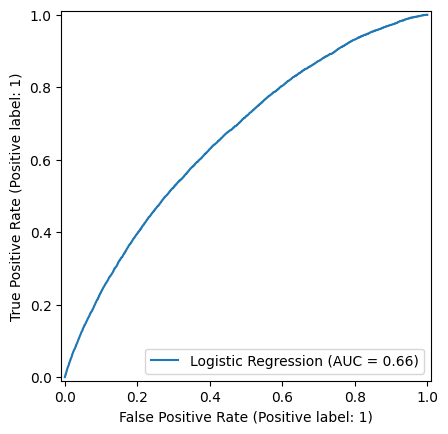

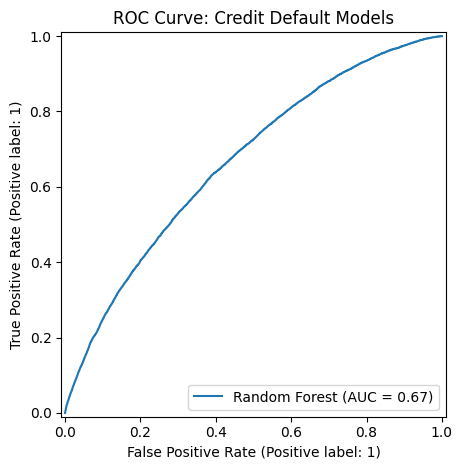

In [20]:

plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test, logistic_prob, name="Logistic Regression"
)
RocCurveDisplay.from_predictions(
    y_test, rf_prob, name="Random Forest"
)

plt.title("ROC Curve: Credit Default Models")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "roc_curve.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()


<Figure size 800x600 with 0 Axes>

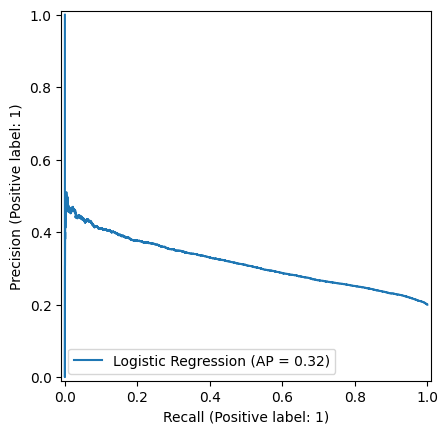

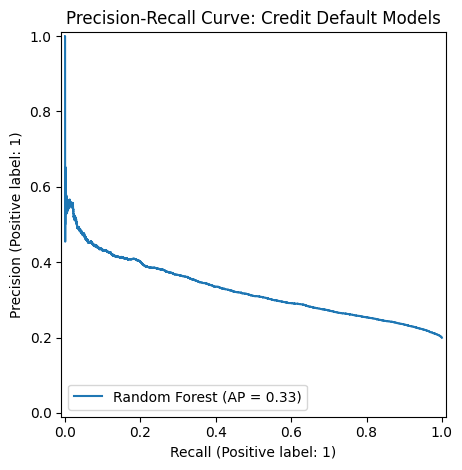

In [21]:

plt.figure(figsize=(8, 6))

PrecisionRecallDisplay.from_predictions(
    y_test, logistic_prob, name="Logistic Regression"
)
PrecisionRecallDisplay.from_predictions(
    y_test, rf_prob, name="Random Forest"
)

plt.title("Precision-Recall Curve: Credit Default Models")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "precision_recall_curve.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()


Selected for initial analysis: Random Forest

Classification report:
              precision    recall  f1-score   support

           0       0.87      0.63      0.73     48020
           1       0.29      0.61      0.39     11980

    accuracy                           0.62     60000
   macro avg       0.58      0.62      0.56     60000
weighted avg       0.75      0.62      0.66     60000



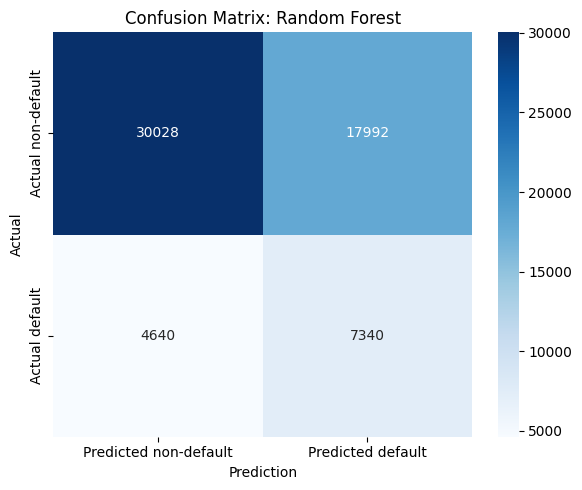

In [22]:

best_name = results.sort_values(
    "ROC_AUC", ascending=False
).iloc[0]["Model"]

if best_name == "Random Forest":
    best_model = rf_model
    best_prob = rf_prob
    best_pred = rf_pred
else:
    best_model = logistic_model
    best_prob = logistic_prob
    best_pred = logistic_pred

print("Selected for initial analysis:", best_name)
print("\nClassification report:")
print(classification_report(y_test, best_pred, zero_division=0))

cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted non-default", "Predicted default"],
    yticklabels=["Actual non-default", "Actual default"]
)
plt.title(f"Confusion Matrix: {best_name}")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()


                        Feature  Importance
                    num__fico_n    0.273681
                     num__dti_n    0.192749
                 num__loan_amnt    0.158127
                   num__revenue    0.097463
                num__issue_year    0.069348
 cat__home_ownership_n_MORTGAGE    0.042600
     cat__home_ownership_n_RENT    0.037348
               num__issue_month    0.027141
       cat__purpose_credit_card    0.025289
             cat__emp_length_NI    0.017553
cat__purpose_debt_consolidation    0.009131
    cat__purpose_small_business    0.007516
      cat__emp_length_10+ years    0.006434
      cat__home_ownership_n_OWN    0.005389
             cat__purpose_other    0.003830


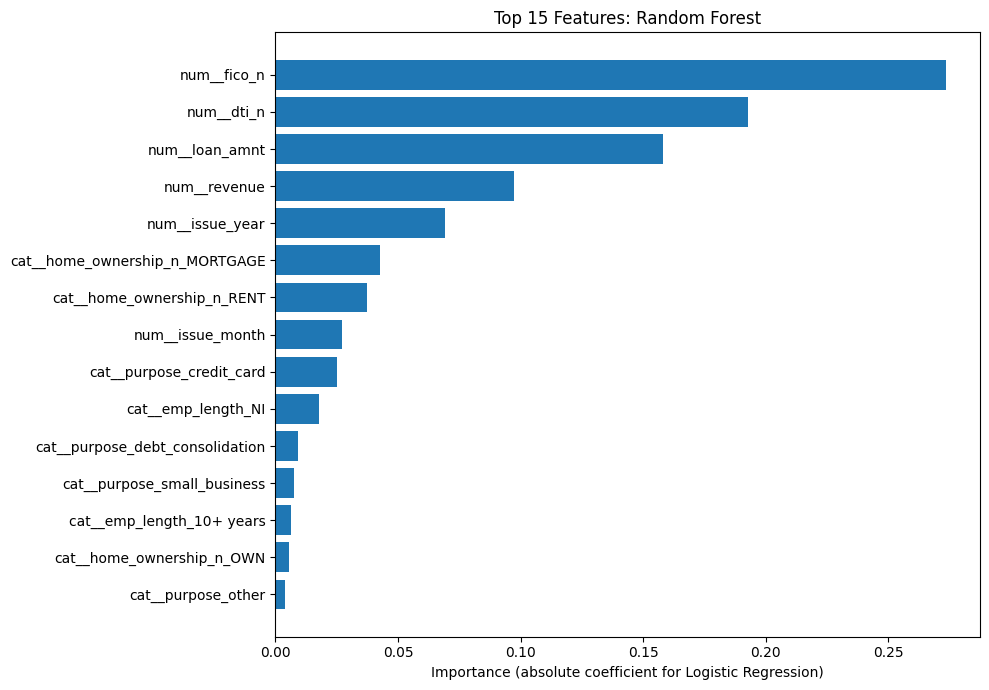

In [23]:

fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_estimator = best_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(fitted_estimator, "feature_importances_"):
    importances = fitted_estimator.feature_importances_
elif hasattr(fitted_estimator, "coef_"):
    importances = np.abs(fitted_estimator.coef_[0])
else:
    raise ValueError("Selected model does not expose feature importance.")

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print(importance_df.head(15).to_string(index=False))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title(f"Top 15 Features: {best_name}")
plt.xlabel("Importance (absolute coefficient for Logistic Regression)")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "feature_importance.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

importance_df.to_csv(
    os.path.join(OUTPUT_DIR, "feature_importance.csv"),
    index=False
)


In [24]:

predictions_df = X_test.copy()
predictions_df["Actual_Default"] = y_test.to_numpy()
predictions_df["Predicted_Default_Probability"] = best_prob
predictions_df["Predicted_Default"] = best_pred

predictions_df["Risk_Band"] = pd.cut(
    predictions_df["Predicted_Default_Probability"],
    bins=[-0.001, 0.10, 0.25, 1.0],
    labels=["Low", "Medium", "High"]
)

predictions_df.to_csv(
    os.path.join(OUTPUT_DIR, "model_predictions.csv"),
    index=False
)

print("Predictions saved.")
print("Selected model:", best_name)
print("Output folder:", OUTPUT_DIR)


Predictions saved.
Selected model: Random Forest
Output folder: /content/drive/MyDrive/FinTech Credit Risk Project/Data/Processed


In [25]:

import joblib

joblib.dump(
    logistic_model,
    os.path.join(OUTPUT_DIR, "logistic_regression_model.joblib")
)

joblib.dump(
    rf_model,
    os.path.join(OUTPUT_DIR, "random_forest_model.joblib")
)

print("Models saved successfully.")


Models saved successfully.
